## Load data from PostgreSQL and save a clean DataFrame

This notebook loads the `telco_customers` table from PostgreSQL, validates the data, creates a clean DataFrame, and saves it as a CSV file.

Main steps:

1. Load the `telco_customers` table from PostgreSQL using the database URL stored in the local `.env` file.
2. Create a clean copy of the DataFrame:
   - Standardize column names.
3. Inspect and validate the data:
   - Check DataFrame dimensions, column names, and data types.
   - Check for duplicate `customer_id` values.
   - Generate a missing values report, with special focus on the target column `churn`.
   - Check unique values and value counts for categorical columns.
   - Review summary statistics and distributions for numerical columns.
4. Save the cleaned DataFrame as a CSV file.

In [1]:
import os

from dotenv import load_dotenv
import matplotlib.pyplot as plt
import pandas as pd

from telco_churn.config import (
    SQL_TABLE,
    TARGET_COLUMN,
    ID_COLUMN,
    BINARY_COLUMN,
    CATEGORICAL_COLUMNS,
    NUMERICAL_COLUMNS,
)
from telco_churn.data_preparation import (
    load_table_to_df,
    save_df_to_csv,
)
from telco_churn.paths import (
    DATA_LOADING_VALIDATION_FIGURES_DIR,
    TELCO_CUSTOMERS_CLEAN_PATH,
)
from telco_churn.plots import save_plot
from telco_churn.toolkit_functions import (
    clean_columns,
    handle_duplicates,
    report_nan,
)

## 1. Load table from PostgreSQL

In [2]:
load_dotenv()
db_url = os.getenv("DB_URL")

df = load_table_to_df(
    db_url=db_url,
    table_name=SQL_TABLE
)

In [3]:
df.head()

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

## 2. Create a DataFrame copy

In [5]:
df_clean = df.copy()
df_clean = clean_columns(df_clean, deal_dups='rename')

## 3. Inspect and validate the data

In [6]:
df_clean.shape

(7043, 21)

In [7]:
df_clean.columns.tolist()

['customer_id',
 'gender',
 'senior_citizen',
 'partner',
 'dependents',
 'tenure',
 'phone_service',
 'multiple_lines',
 'internet_service',
 'online_security',
 'online_backup',
 'device_protection',
 'tech_support',
 'streaming_tv',
 'streaming_movies',
 'contract',
 'paperless_billing',
 'payment_method',
 'monthly_charges',
 'total_charges',
 'churn']

In [8]:
df_clean.dtypes

customer_id           object
gender                object
senior_citizen         int64
partner               object
dependents            object
tenure                 int64
phone_service         object
multiple_lines        object
internet_service      object
online_security       object
online_backup         object
device_protection     object
tech_support          object
streaming_tv          object
streaming_movies      object
contract              object
paperless_billing     object
payment_method        object
monthly_charges      float64
total_charges        float64
churn                 object
dtype: object

In [9]:
handle_duplicates(
    df_clean,
    subset=ID_COLUMN,
    action='report',
)

{'subset_used': ['customer_id'], 'total_num': np.int64(0), 'total_pct': 0.0}

In [10]:
report_nan(
    df_clean,
    target=TARGET_COLUMN,
)

{'total_nan': np.int64(0),
 'columns_with_nan': [],
 'target': {'column_name': 'churn',
  'nan_total': np.int64(0),
  'nan_pct': np.float64(0.0)}}

In [11]:
all_categorical_columns = CATEGORICAL_COLUMNS + (BINARY_COLUMN, TARGET_COLUMN)

for col in all_categorical_columns:
    display(df_clean[col].value_counts())
    print()

gender
Male      3555
Female    3488
Name: count, dtype: int64

partner
No     3641
Yes    3402
Name: count, dtype: int64

dependents
No     4933
Yes    2110
Name: count, dtype: int64

phone_service
Yes    6361
No      682
Name: count, dtype: int64

multiple_lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

...

contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

paperless_billing
Yes    4171
No     2872
Name: count, dtype: int64

payment_method
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

senior_citizen
0    5901
1    1142
Name: count, dtype: int64

churn
No     5174
Yes    1869
Name: count, dtype: int64

In [12]:
df_clean[list(NUMERICAL_COLUMNS)].describe()

,tenure,monthly_charges,total_charges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


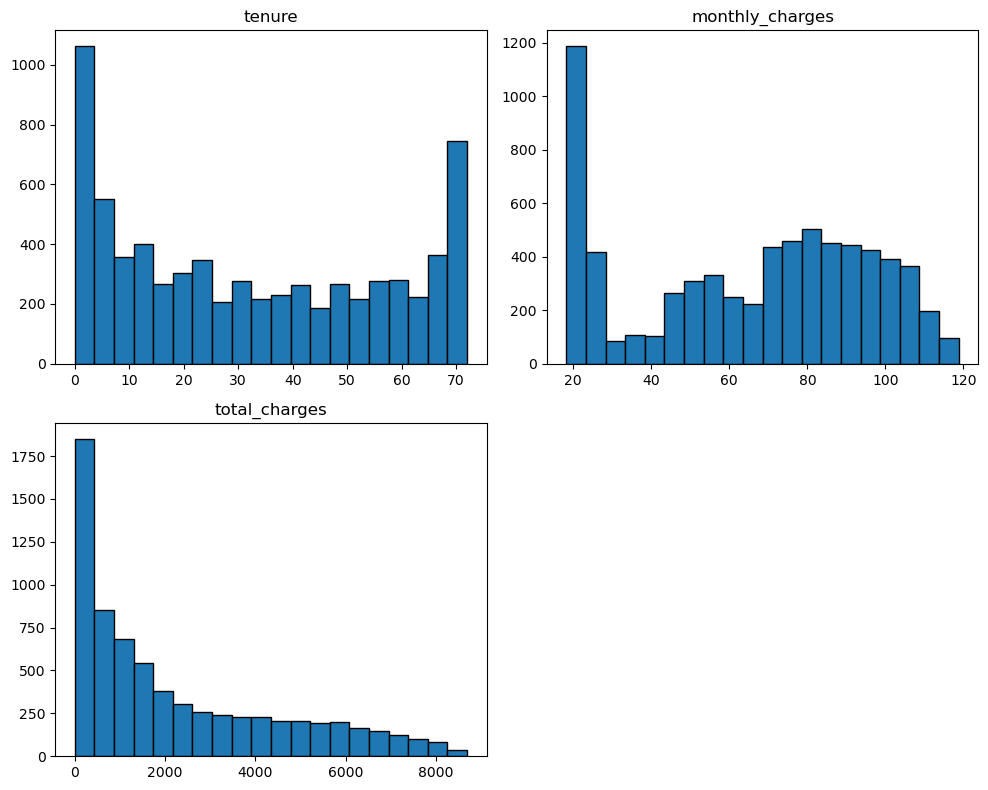

In [15]:
df_clean[list(NUMERICAL_COLUMNS)].hist(
    bins=20,
    figsize=(10, 8),
    edgecolor='black',
    sharex=False,
    sharey=False,
    grid=False,
)
plt.tight_layout()
save_plot(
    path=DATA_LOADING_VALIDATION_FIGURES_DIR,
    file_name='numerical_columns_histogram'
)
plt.show()

### Summary

Numerical features are not normally distributed. `tenure` has strong peaks among new and long-tenure customers, `monthly_charges` shows visible customer segments, and `total_charges` is right-skewed with many low values.

## 4. Save the cleaned DataFrame as a CSV file

In [14]:
df_clean_path = save_df_to_csv(
    df=df_clean,
    path=TELCO_CUSTOMERS_CLEAN_PATH,
)

## Summary

The data loading and validation step confirms that the dataset is ready for train-test split and further EDA.

Key outputs from this notebook:
- Clean DataFrame saved to `data/processed/telco_customers_clean.csv`
- Numerical histogram saved to `reports/figures/data_loading_validation/numerical_columns_histogram.png`